In [ ]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


In [18]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import os

from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

sns.set_style("whitegrid")

print("All libraries imported successfully!")

All libraries imported successfully!


In [19]:
file_path = '/content/drive/MyDrive/CODE_ALPHA_INTERNSHIP/Advertising.csv'

df = pd.read_csv(file_path)

print("Dataset loaded successfully!")
print("Dataset shape:", df.shape)

display(df.head())

Dataset loaded successfully!
Dataset shape: (200, 5)


,Unnamed: 0,TV,Radio,Newspaper,Sales
0,1,230.1,37.8,69.2,22.1
1,2,44.5,39.3,45.1,10.4
2,3,17.2,45.9,69.3,9.3
3,4,151.5,41.3,58.5,18.5
4,5,180.8,10.8,58.4,12.9


In [20]:
# Remove extra spaces from column names
df.columns = df.columns.str.strip()

# Remove unnamed index column if present
df = df.loc[:, ~df.columns.str.lower().str.startswith('unnamed')]

# Convert columns into numeric format
columns = ['TV', 'Radio', 'Newspaper', 'Sales']

for col in columns:
    df[col] = pd.to_numeric(df[col], errors='coerce')

# Remove missing values
df.dropna(subset=columns, inplace=True)

# Remove duplicate records
df.drop_duplicates(inplace=True)

# Reset index
df.reset_index(drop=True, inplace=True)

print("Data cleaning completed!")
print("Cleaned dataset shape:", df.shape)

display(df.head())

Data cleaning completed!
Cleaned dataset shape: (200, 4)


,TV,Radio,Newspaper,Sales
0,230.1,37.8,69.2,22.1
1,44.5,39.3,45.1,10.4
2,17.2,45.9,69.3,9.3
3,151.5,41.3,58.5,18.5
4,180.8,10.8,58.4,12.9


In [ ]:
#Perform exploratory data analysis
print("Average TV Advertising:", df['TV'].mean())

print("Average Radio Advertising:", df['Radio'].mean())

print("Average Newspaper Advertising:", df['Newspaper'].mean())

print("Average Sales:", df['Sales'].mean())

Average TV Advertising: 147.0425
Average Radio Advertising: 23.264000000000006
Average Newspaper Advertising: 30.553999999999995
Average Sales: 14.0225


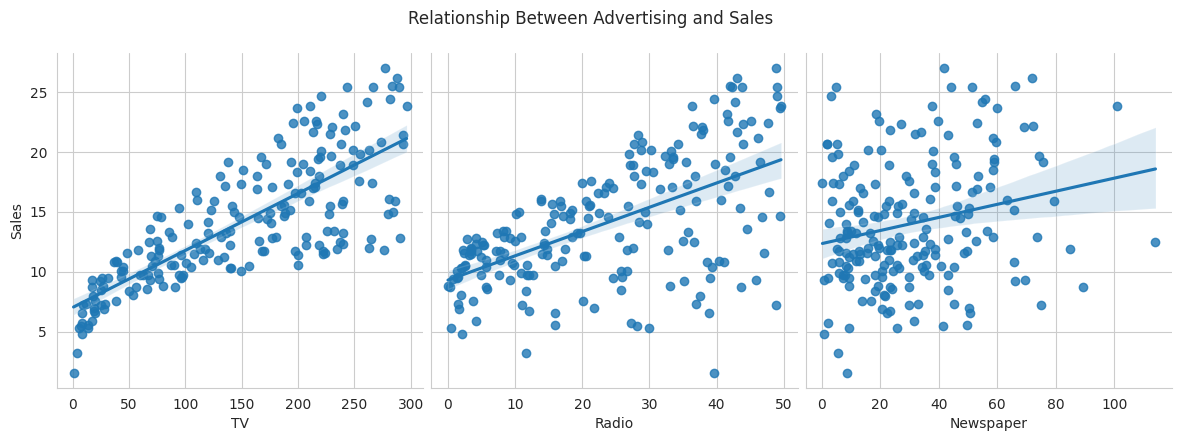

In [ ]:
#Visualize the relationship between advertising and sales
sns.pairplot(
    df,
    x_vars=['TV', 'Radio', 'Newspaper'],
    y_vars='Sales',
    height=4,
    kind='reg'
)

plt.suptitle(
    'Relationship Between Advertising and Sales',
    y=1.08
)

plt.show()

Correlation Matrix:


,TV,Radio,Newspaper,Sales
TV,1.000000,0.054809,0.056648,0.782224
Radio,0.054809,1.000000,0.354104,0.576223
Newspaper,0.056648,0.354104,1.000000,0.228299
Sales,0.782224,0.576223,0.228299,1.000000


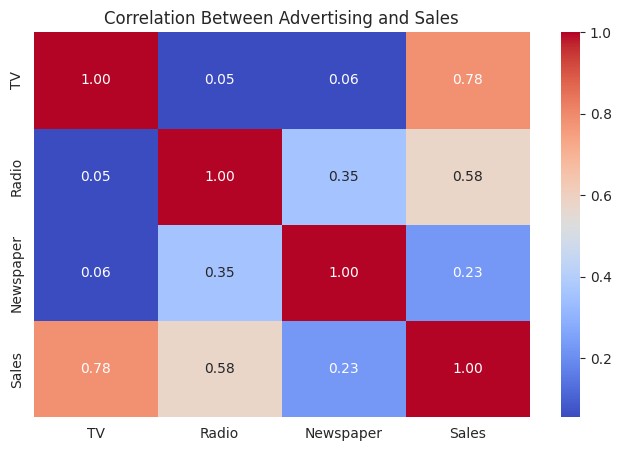

In [ ]:
#Correlation analysis
correlation = df.corr(numeric_only=True)

print("Correlation Matrix:")
display(correlation)

plt.figure(figsize=(8, 5))

sns.heatmap(
    correlation,
    annot=True,
    cmap='coolwarm',
    fmt='.2f'
)

plt.title('Correlation Between Advertising and Sales')

plt.show()

In [ ]:
#Select independent and dependent variables
X = df[['TV', 'Radio', 'Newspaper']]

y = df['Sales']

print("Independent Variables:")
display(X.head())

print("Dependent Variable:")
display(y.head())

Independent Variables:


,TV,Radio,Newspaper
0,230.1,37.8,69.2
1,44.5,39.3,45.1
2,17.2,45.9,69.3
3,151.5,41.3,58.5
4,180.8,10.8,58.4


Dependent Variable:


,Sales
0,22.1
1,10.4
2,9.3
3,18.5
4,12.9


In [ ]:
#Split the dataset into training and testing data
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42
)

print("Training data:", X_train.shape)

print("Testing data:", X_test.shape)

Training data: (160, 3)
Testing data: (40, 3)


In [ ]:
#Build the Linear Regression model
model = LinearRegression()

model.fit(X_train, y_train)

print("Linear Regression Model Trained Successfully!")

print("Intercept:", model.intercept_)

print("Coefficients:", model.coef_)

Linear Regression Model Trained Successfully!
Intercept: 2.979067338122629
Coefficients: [0.04472952 0.18919505 0.00276111]


In [ ]:
#Predict sales
y_pred = model.predict(X_test)

results = pd.DataFrame({
    'Actual Sales': y_test.values,
    'Predicted Sales': y_pred
})

display(results.head(10))

,Actual Sales,Predicted Sales
0,16.9,16.408024
1,22.4,20.889882
2,21.4,21.553843
3,7.3,10.608503
4,24.7,22.112373
5,12.6,13.105592
6,22.3,21.057192
7,8.4,7.461010
8,11.5,13.606346
9,14.9,15.155070


In [ ]:
#Evaluate model performance
mae = mean_absolute_error(y_test, y_pred)

mse = mean_squared_error(y_test, y_pred)

rmse = np.sqrt(mse)

r2 = r2_score(y_test, y_pred)

print("MODEL PERFORMANCE")

print("MAE:", round(mae, 3))

print("MSE:", round(mse, 3))

print("RMSE:", round(rmse, 3))

print("R2 Score:", round(r2, 3))

MODEL PERFORMANCE
MAE: 1.461
MSE: 3.174
RMSE: 1.782
R2 Score: 0.899


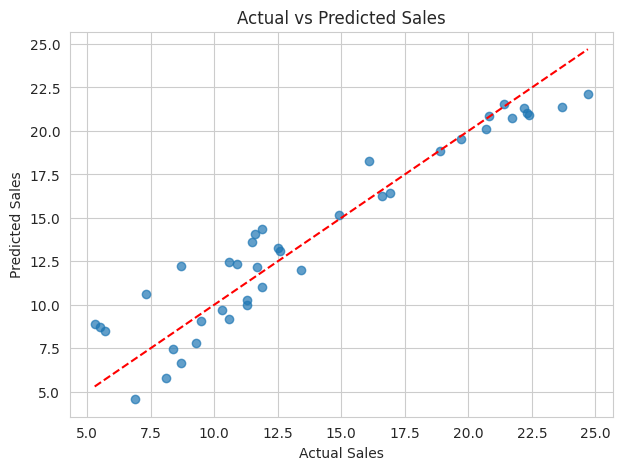

In [ ]:
#Actual vs predicted sales visualization
plt.figure(figsize=(7, 5))

plt.scatter(y_test, y_pred, alpha=0.7)

plt.plot(
    [y_test.min(), y_test.max()],
    [y_test.min(), y_test.max()],
    'r--'
)

plt.xlabel("Actual Sales")

plt.ylabel("Predicted Sales")

plt.title("Actual vs Predicted Sales")

plt.show()

Advertising Channel Coefficients:
Radio        0.189195
TV           0.044730
Newspaper    0.002761
dtype: float64


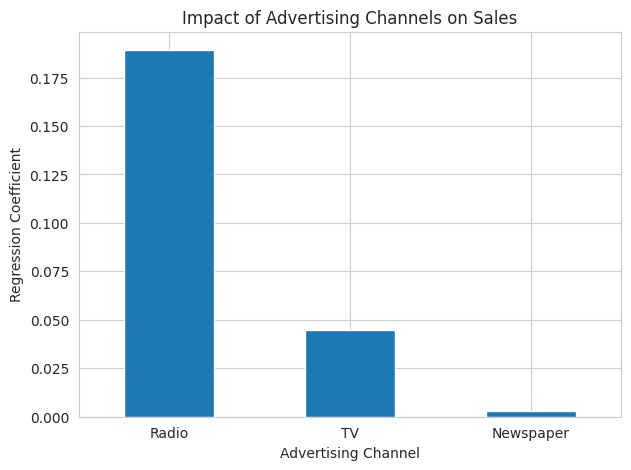

In [ ]:
#Identify the most influential advertising channel
importance = pd.Series(
    model.coef_,
    index=X.columns
).sort_values(ascending=False)

print("Advertising Channel Coefficients:")
print(importance)

plt.figure(figsize=(7, 5))

importance.plot(kind='bar')

plt.xlabel("Advertising Channel")

plt.ylabel("Regression Coefficient")

plt.title("Impact of Advertising Channels on Sales")

plt.xticks(rotation=0)

plt.show()

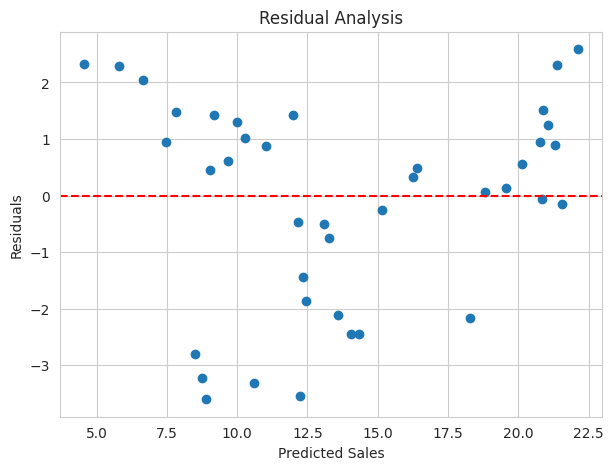

In [ ]:
#Residual analysis
residuals = y_test - y_pred

plt.figure(figsize=(7, 5))

plt.scatter(y_pred, residuals)

plt.axhline(y=0, color='red', linestyle='--')

plt.xlabel("Predicted Sales")

plt.ylabel("Residuals")

plt.title("Residual Analysis")

plt.show()

In [ ]:
#Predict sales for a new advertising budget
new_data = pd.DataFrame({
    'TV': [150],
    'Radio': [25],
    'Newspaper': [10]
})

prediction = model.predict(new_data)

print("Predicted Sales:", round(prediction[0], 2))

Predicted Sales: 14.45


In [ ]:
#Generate business insights
print("========== BUSINESS INSIGHTS ==========")

print("Most influential channel:", importance.idxmax())

print("Least influential channel:", importance.idxmin())

print("Model R2 Score:", round(r2, 3))

print("\nRecommendation:")

print(
    "Advertising channels with stronger positive regression "
    "coefficients may offer greater sales contribution. "
    "Marketing decisions should also consider campaign costs."
)

========== BUSINESS INSIGHTS ==========
Most influential channel: Radio
Least influential channel: Newspaper
Model R2 Score: 0.899

Recommendation:
Advertising channels with stronger positive regression coefficients may offer greater sales contribution. Marketing decisions should also consider campaign costs.
